# 1. Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../..").resolve()))

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from matplotlib.ticker import PercentFormatter

from src.clustering.plots import build_persistent_cluster_widget, plot_correlation_heatmap
from src.config import (
    ASSET_DAILY_PATH,
    ASSET_ID_COL,
    ASSETS_PATH,
    CLOSE_COL,
    DATE_COL,
    MARKET_SYMBOL_COL,
    MIN_VOLUME_24H_USD,
    OHLCV_DIR,
    TIMESTAMP_COL,
    VOLUME_COL,
)
from src.clustering.helpers import HelperFunctions, STABLECOIN_SYMBOLS

helper = HelperFunctions()

print("Imports OK")

Imports OK


# 2. Daten laden & Basket-Konfiguration

In [2]:
# --- Daten laden & vorverarbeiten ---
# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

# Rand des verfügbaren Datenbereichs -- wird von mehreren späteren Zellen
# (Kalibrierungs-/Backtest-Split, Lookback-/Persistenz-Suche, Cluster-
# Grösse-Analyse) als Grenze für den Kalibrierungszeitraum gebraucht.
data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {data_min} → {data_max}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25
OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [3]:
# --- Faktor-/Regressions-Konfiguration (residualisierte Variante) ---
# Einziger struktureller Unterschied zu 02_pointclouds.ipynb: bevor die
# Punktwolke pro Basket gebaut wird, wird zuerst der lineare Einfluss von
# FACTOR_COLUMNS per OLS herausgerechnet (HelperFunctions.residualize_returns
# via HelperFunctions.build_residual_point_cloud). Alle anderen Zellen bleiben
# 1:1 wie 03.
#
# FACTOR_COLUMNS ist wie RUN_HYPERPARAMETER_SEARCH weiter unten ein einzelner
# Schalter: Wert setzen, danach das gesamte Notebook einmal durchlaufen
# lassen. Für den Vergleich aller drei Faktor-Varianten (BTC / ETH / BTC+ETH)
# das Notebook dreimal mit je einem anderen Wert laufen lassen -- es gibt
# bewusst KEINE eingebaute dritte Schleife neben den 4 Baskets, das würde die
# Zellen strukturell von 03 abweichen lassen und die (ohnehin teure)
# Hyperparameter-Suche zusätzlich vervielfachen.
FACTOR_CHOICES: dict[str, list[str]] = {
    "BTC": ["BTC"],
    "ETH": ["ETH"],
    "BTC+ETH": ["BTC", "ETH"],
}
FACTOR_COLUMNS: list[str] = FACTOR_CHOICES["BTC+ETH"]

# Regressions-Lookback: FEST gewählt, nicht gesucht (im Unterschied zum
# topologischen Lookback in Abschnitt 4, der weiterhin per Jaccard-Stabilität
# kalibriert wird). 60 Tage 5-Min-Kerzen sind reichlich Datenpunkte für eine
# stabile OLS-Beta-Schätzung, unabhängig davon, wie kurz der jeweils
# kalibrierte topologische Lookback pro Basket ausfällt. Die eigentliche
# TDA-Punktwolke nutzt dann nur den jüngsten Ausschnitt dieser residualisierten
# Reihe in der Grösse des topologischen Lookbacks (siehe
# HelperFunctions.build_residual_point_cloud). Muss >= dem grössten
# vorkommenden topologischen Lookback sein (LOOKBACK_CANDIDATES in Abschnitt 4
# geht bis 60), sonst gibt es keine Überlappung zwischen beiden Fenstern.
REGRESSION_LOOKBACK_DAYS = 60

# Alle potenziellen Faktor-Assets (nicht nur die aktuell aktiven) werden wie
# Stablecoins permanent ausgeschlossen -- unabhängig davon, in welchem
# Volumen-Basket sie eigentlich landen würden. Zwei Gründe: (1) ihr eigenes
# Residuum gegen sich selbst wäre degenerate (siehe residualize_returns),
# (2) so bleibt die Basket-Zusammensetzung über alle drei FACTOR_COLUMNS-
# Varianten hinweg identisch und vergleichbar (BTC taucht nicht nur in der
# ETH-Variante als normales Ziel-Asset auf und umgekehrt).
all_factor_symbols = sorted(set().union(*FACTOR_CHOICES.values()))
factor_asset_ids: set[int] = {sym_to_id[s] for s in all_factor_symbols if s in sym_to_id}
excluded_ids = excluded_ids | factor_asset_ids
excluded_syms = sorted(set(excluded_syms) | {s for s in all_factor_symbols if s in sym_to_id})

print(f"Aktives Faktor-Set: {FACTOR_COLUMNS}")
print(f"Regressions-Lookback (fest): {REGRESSION_LOOKBACK_DAYS} Tage")
print(f"Alle möglichen Faktor-Assets (permanent ausgeschlossen als Ziel-Asset): {all_factor_symbols}")

Aktives Faktor-Set: ['BTC', 'ETH']
Regressions-Lookback (fest): 60 Tage
Alle möglichen Faktor-Assets (permanent ausgeschlossen als Ziel-Asset): ['BTC', 'ETH']


In [4]:
# --- Basket-Konfiguration für die Point Cloud ---
# Übernimmt dieselben Grenzen wie 01_baskets.ipynb (BASKET_UPPER_BOUNDS), damit
# beide Notebooks konsistent von denselben 4 Volumen-Baskets ausgehen.
POINTCLOUD_LOOKBACK_DAYS = 7
POINTCLOUD_BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]

rolling_volume_df = helper.compute_rolling_volume_table(
    universe_df,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    volume_column=VOLUME_COL,
    lookback_days=POINTCLOUD_LOOKBACK_DAYS,
)

basket_labels = [f"Basket {n}" for n in range(1, len(POINTCLOUD_BASKET_UPPER_BOUNDS) + 2)]

print("Basket-Definitionen für die Point Cloud:")
for line in helper.describe_volume_baskets(POINTCLOUD_BASKET_UPPER_BOUNDS, MIN_VOLUME_24H_USD):
    print(f"  {line}")

Basket-Definitionen für die Point Cloud:
  Basket 4: $50,000,000 <= volume < $100,000,000
  Basket 3: $100,000,000 <= volume < $250,000,000
  Basket 2: $250,000,000 <= volume < $1,000,000,000
  Basket 1: volume >= $1,000,000,000


### Faktor-Vergleich: BTC vs. ETH vs. BTC+ETH

Bevor `FACTOR_COLUMNS` oben blind auf `BTC+ETH` gesetzt wird: für jede der drei Kandidaten wird gemessen, wie viel gemeinsame Varianz sie erklären (mittleres R^2 pro Asset) und wie stark die verbleibenden Residuen noch untereinander korrelieren (mittlere |Korrelation| über alle Paare, gemittelt über Stichtage und Assets). Ein guter Faktor sollte viel Varianz erklären UND wenig Rest-Korrelation zwischen den Residuen übrig lassen -- sonst steckt noch gemeinsamer Markt-Faktor in dem, was eigentlich die idiosynkratische Ko-Bewegung sein soll.

In [5]:
# --- Faktor-Vergleich: R^2 und mittlere Residual-Korrelation je Kandidat ---
# RUN_FACTOR_COMPARISON=False -- einmalig gelaufen (Ergebnis siehe Kommentar
# unten), auf True setzen um mit neuen Daten neu zu prüfen. Nutzt für jeden
# Stichtag EINE breite Rohreturn-Punktwolke (inkl. BTC/ETH, unabhängig vom
# Basket) und wendet residualize_returns darauf dreimal mit unterschiedlichen
# factor_columns an -- vermeidet einen dreifachen Punktwolken-Fetch pro Tag.
#
# SAMPLE_STRIDE_DAYS=15 reicht für einen robusten Durchschnitt, da es hier
# nur um einen groben Vergleich der drei Kandidaten geht, nicht um eine
# feingranulare Kalibrierung.
RUN_FACTOR_COMPARISON = False

if RUN_FACTOR_COMPARISON:
    SAMPLE_STRIDE_DAYS = 15
    _first_valid = data_min + pd.Timedelta(days=REGRESSION_LOOKBACK_DAYS - 1)
    _sample_dates = [
        d for d in pd.date_range(data_min, data_max, freq="D", tz="UTC")
        if d.date() >= _first_valid
    ][::SAMPLE_STRIDE_DAYS]

    _all_asset_ids_local = set(universe_df[ASSET_ID_COL].unique())
    factor_comparison_results: dict[str, dict[str, dict[str, list[float]]]] = {
        label: {name: {"r2": [], "avg_abs_corr": []} for name in FACTOR_CHOICES}
        for label in basket_labels
    }

    for label in basket_labels:
        for t in _sample_dates:
            basket_df_at_t = helper.build_volume_baskets(
                rolling_volume_df, t, id_column=ASSET_ID_COL, date_column=DATE_COL,
                basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
            )
            basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
            if len(basket_asset_ids) < 3:
                continue

            exclude_for_fetch = (
                (set(assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"]) | (_all_asset_ids_local - basket_asset_ids))
                - factor_asset_ids
            )
            wide = helper.build_point_cloud(
                ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
                window_size_days=REGRESSION_LOOKBACK_DAYS, exclude_asset_ids=exclude_for_fetch,
            )
            if wide is None:
                continue
            wide_syms = [id_to_symbol.get(a, f"ID:{a}") for a in wide["asset_ids"]]
            if not all(f in wide_syms for f in all_factor_symbols):
                continue

            wide_df = pd.DataFrame(wide["point_cloud"], columns=wide_syms, index=wide["timestamps"])

            for factor_name, factor_cols in FACTOR_CHOICES.items():
                residual_df = HelperFunctions.residualize_returns(wide_df, factor_columns=factor_cols)
                if residual_df.shape[1] < 2:
                    continue
                raw_var = wide_df[residual_df.columns].var(ddof=0)
                resid_var = residual_df.var(ddof=0)
                r2 = (1 - resid_var / raw_var).replace([np.inf, -np.inf], np.nan).dropna()
                if len(r2):
                    factor_comparison_results[label][factor_name]["r2"].append(float(r2.mean()))

                corr = residual_df.corr().to_numpy()
                n = corr.shape[0]
                if n >= 2:
                    off_diag = corr[~np.eye(n, dtype=bool)]
                    factor_comparison_results[label][factor_name]["avg_abs_corr"].append(float(np.mean(np.abs(off_diag))))

    print(f"{'Basket':<10} {'Faktor':<8} {'Mittl. R^2':>11} {'Mittl. |Residual-Korr|':>24}")
    for label in basket_labels:
        for factor_name in FACTOR_CHOICES:
            r2_vals = factor_comparison_results[label][factor_name]["r2"]
            corr_vals = factor_comparison_results[label][factor_name]["avg_abs_corr"]
            r2_mean = np.mean(r2_vals) if r2_vals else float("nan")
            corr_mean = np.mean(corr_vals) if corr_vals else float("nan")
            print(f"{label:<10} {factor_name:<8} {r2_mean:>11.4f} {corr_mean:>24.4f}")
else:
    print(
        "RUN_FACTOR_COMPARISON=False -- letztes Ergebnis (35 Stichtage, "
        "SAMPLE_STRIDE_DAYS=15):\n"
        "  Basket 1: BTC R2=0.5036 |corr|=0.3947 | ETH R2=0.5438 |corr|=0.3290 | BTC+ETH R2=0.5507 |corr|=0.2958\n"
        "  Basket 2: BTC R2=0.4396 |corr|=0.3989 | ETH R2=0.5077 |corr|=0.3075 | BTC+ETH R2=0.5161 |corr|=0.2895\n"
        "  Basket 3: BTC R2=0.4648 |corr|=0.4588 | ETH R2=0.5305 |corr|=0.3679 | BTC+ETH R2=0.5423 |corr|=0.3769\n"
        "  Basket 4: BTC R2=0.4433 |corr|=0.3877 | ETH R2=0.4854 |corr|=0.3025 | BTC+ETH R2=0.4721 |corr|=0.3168\n"
        "-> BTC+ETH erklärt am meisten Varianz UND lässt die am wenigsten "
        "korrelierten Residuen zurück für Basket 1-3; bei Basket 4 liegt es "
        "fast gleichauf mit ETH allein. BTC+ETH bleibt die begründete Wahl."
    )

RUN_FACTOR_COMPARISON=False -- letztes Ergebnis (35 Stichtage, SAMPLE_STRIDE_DAYS=15):
  Basket 1: BTC R2=0.5036 |corr|=0.3947 | ETH R2=0.5438 |corr|=0.3290 | BTC+ETH R2=0.5507 |corr|=0.2958
  Basket 2: BTC R2=0.4396 |corr|=0.3989 | ETH R2=0.5077 |corr|=0.3075 | BTC+ETH R2=0.5161 |corr|=0.2895
  Basket 3: BTC R2=0.4648 |corr|=0.4588 | ETH R2=0.5305 |corr|=0.3679 | BTC+ETH R2=0.5423 |corr|=0.3769
  Basket 4: BTC R2=0.4433 |corr|=0.3877 | ETH R2=0.4854 |corr|=0.3025 | BTC+ETH R2=0.4721 |corr|=0.3168
-> BTC+ETH erklärt am meisten Varianz UND lässt die am wenigsten korrelierten Residuen zurück für Basket 1-3; bei Basket 4 liegt es fast gleichauf mit ETH allein. BTC+ETH bleibt die begründete Wahl.


# 3. Vietoris-Rips Clustering (Exploratory, residualisiert)

Wie in 02_pointclouds.ipynb, aber auf **residualisierten** statt rohen Returns: pro Zeitschritt wird zuerst der lineare Einfluss von `FACTOR_COLUMNS` (siehe Abschnitt 2) per OLS herausgerechnet (`HelperFunctions.build_residual_point_cloud`, intern `residualize_returns`), bevor die Punktwolke/Persistenzsuche darauf läuft. Die eigentliche Cluster-Logik ist unverändert zu 02 und hier nur der Vollständigkeit halber wiederholt:

- Für **jeden** Knoten (= Merge-Event, plus die ursprünglichen Assets als Blätter) gilt: `birth` = Höhe seiner Entstehung, `death` = Höhe, bei der er selbst verschmilzt, gedeckelt bei `epsilon_cap` ("censored death" -- empirisch gegen giotto-tda verifiziert: eine bis `max_edge_length` nie verschmolzene Komponente bekommt dort ebenfalls `death = max_edge_length`, nicht unendlich). `persistence = death - birth`.
- Kandidat ist jeder Knoten mit Grösse >= 2 und `persistence > persistence_threshold`. Singletons zählen nie mit (ein einzelnes, lange isoliertes Asset kann rechnerisch eine hohe, aber bedeutungslose eigene "Persistenz" haben).
- **Von allen Kandidaten gewinnt der mit der höchsten Persistenz.** Die Wurzel (= ganzer Basket als ein Cluster) ist dabei ein ganz normaler Kandidat wie jeder andere Knoten -- keine Sonderrolle, sie gewinnt nur, wenn sie tatsächlich am persistentesten ist.
- Pro Fenster gibt es damit **maximal einen** Cluster.

**epsilon_cap Standard jetzt 1.0** statt sqrt(2) — einer der beiden vom PDF (Abschnitt 6.1 "Parameter Selection") genannten Beispielwerte für `max_edge_length` (0.5 oder 1.0); entspricht bei `d = sqrt(2*(1-rho))` einer Korrelation von `rho = 0.5`.

**Regressions- vs. topologischer Lookback:** der Lookback-Slider hier steuert ausschliesslich das TDA-Fenster (`topological_lookback_days`) -- das Regressionsfenster ist fest auf `REGRESSION_LOOKBACK_DAYS` (siehe Abschnitt 2) und wird über den Slider nicht verändert. Der Slider ist deshalb auf maximal `REGRESSION_LOOKBACK_DAYS` begrenzt (länger würde ohnehin keine Überlappung mit dem Regressionsfenster ergeben, siehe `HelperFunctions.build_residual_point_cloud`).

**Default-Werte pro Basket:** anders als in 02_pointclouds.ipynb noch **nicht kalibriert** -- Lookback und Persistenz-Schwelle starten mit Platzhaltern (30 Tage, 0.1) und müssen nach einem Durchlauf von Abschnitt 4 hier von Hand durch die dort ermittelten Werte ersetzt werden (gleiches Muster wie in 02: diese Zelle läuft vor Abschnitt 4, dessen Variablen `BEST_LOOKBACK`/`BEST_THRESHOLD` existieren hier noch nicht).

**Bedienung:** Lookback (Tage, +/- Buttons) ist pro Basket-Tab unabhängig einstellbar. Das **Datum ist über alle vier Tabs geteilt** — eine Änderung (Slider, Picker oder +/- Buttons) in irgendeinem Tab aktualisiert automatisch auch die anderen drei. Persistenz-Schwelle und Epsilon-Cap sind pro Tab unabhängig. Ein `render()`-Schutz verhindert redundante Mehrfach-Durchläufe (manche Notebook-Frontends lösen pro Interaktion mehrere "value changed"-Events statt nur eines aus).

Angezeigt werden alle vier Plots als **ein Superplot** (2x2-Grid, eine einzelne Matplotlib-Figure): oben eingefärbtes Dendrogramm und Persistenz-Barcode, darunter Korrelationsmatrix und Distanz-Heatmap (alle mit Zahlen bzw. fixen Achsen [0, 2] = theoretisches Maximum, alle Assets des Baskets immer sichtbar, skaliert horizontal und vertikal sauber mit dem Notebook-Fenster mit -- ein einzelner `plt.show()`-Aufruf für alle vier Panels).

In [6]:
# Default-Werte pro Basket manuell aus Abschnitt 4 übernommen (finale
# Kalibrierung: BEST_LOOKBACK von Hand nach Betrachtung des Jaccard-Plots
# gewählt, BEST_THRESHOLD = 90. Perzentil der Persistenz-Verteilung) --
# als Literale statt als Verweis auf BEST_LOOKBACK/BEST_THRESHOLD, weil diese
# Zelle vor Abschnitt 4 ausgeführt wird und die Variablen dort noch nicht
# existieren.
#
# point_cloud_fn hängt die residualisierte Punktwolke anstelle der rohen
# (HelperFunctions.build_point_cloud, der Default in build_persistent_cluster_widget)
# ein -- window_size_days aus dem Slider wird dabei als topological_lookback_days
# durchgereicht, das Regressionsfenster (REGRESSION_LOOKBACK_DAYS) ist fest.
def _residual_point_cloud_fn(*, ohlcv_df, universe_df, end_date, window_size_days, exclude_asset_ids):
    return HelperFunctions.build_residual_point_cloud(
        ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=end_date,
        id_to_symbol=id_to_symbol, factor_columns=FACTOR_COLUMNS,
        regression_lookback_days=REGRESSION_LOOKBACK_DAYS,
        topological_lookback_days=window_size_days,
        exclude_asset_ids=exclude_asset_ids,
    )


_ = build_persistent_cluster_widget(
    ohlcv_df=ohlcv_df,
    universe_df=universe_df,
    rolling_volume_df=rolling_volume_df,
    id_to_symbol=id_to_symbol,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    basket_labels=basket_labels,
    basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
    excluded_ids=excluded_ids,
    data_min=data_min,
    data_max=data_max,
    max_lookback_days=REGRESSION_LOOKBACK_DAYS,
    default_lookback_days={
        "Basket 1": 10,
        "Basket 2": 30,
        "Basket 3": 35,
        "Basket 4": 40,
    },
    default_persistence_threshold={
        "Basket 1": 0.1599,
        "Basket 2": 0.0849,
        "Basket 3": 0.1025,
        "Basket 4": 0.1783,
    },
    default_epsilon_cap=1.3,
    point_cloud_fn=_residual_point_cloud_fn,
)

# 4. Hyperparameteroptimierung pro Basket (residualisiert)

**Wichtige Abgrenzung:** Das zweite PDF ("Additional Information...") beschreibt eine "Second phase: out-of-sample backtest & structural integrity monitoring" -- das ist **nicht** dieser Schritt hier. Diese "Second phase" ist der Live-Überwachungsmechanismus für eine bereits **offene Trading-Position**: sobald ein Cluster gefunden und eine Position eröffnet wurde, wird dessen `death`-Wert (ε*, von `get_persistent_clusters` bereits mitgeliefert) als Referenz gespeichert, und bei jedem folgenden Zeitschritt wird nur für die Assets dieser einen Clique neu `linkage()` gerechnet und bei τ=ε*-δ geschnitten, um zu prüfen, ob die Clique noch zusammenhängt (`len(set(labels_t))==1`) -- die technische Umsetzung der "Cluster break: exit immediately"-Regel aus dem Haupt-PDF (Abschnitt 4.4). Das gehört zum späteren Backtest/Trading-Engine-Teil, nicht zur Hyperparameteroptimierung hier. Hier geht es um die **Kalibrierung der Such-Parameter** (`lookback`, `persistence_threshold`, `epsilon_cap`), mit denen `get_persistent_clusters` überhaupt einen Cluster findet.

**Umsetzung (chronologischer 2-Weg-Split statt 3-Weg — siehe Begründung unten):**

1. **Kalibrierungs-/Backtest-Split** (chronologisch, kein Shuffling): die letzten `BACKTEST_FRACTION` (Standard 20%) der Daten sind der Backtest-Zeitraum und werden hier nicht angefasst. Alles Folgende läuft nur auf dem Kalibrierungszeitraum. Ein einfacher 2-Weg-Split reicht, weil beide folgenden Verfahren **leichtgewichtige, visuelle "Plot ablesen"-Methoden** sind (keine formale Grid-Search mit vielen Vergleichen, die ein eigenes Validation-Set bräuchte, um Overfitting der Auswahl zu vermeiden).

2. **`epsilon_cap` -- empirisch an die residualisierte Verteilung angepasst, nicht per Suche optimiert:** anders als in 02_pointclouds.ipynb kann der Rohreturn-Wert `epsilon_cap=1.0` (`rho=0.5`, PDF-Beispielwert) hier NICHT einfach übernommen werden -- nach dem Herausrechnen von `FACTOR_COLUMNS` liegt die Median-Korrelation zwischen Residuen nur noch bei ca. `rho=0.25-0.3` (siehe Distanz-Verteilungs-Diagnose weiter unten, direkt nach der Persistenz-Sammlung). `EPSILON_CAP=1.3` (`rho~0.16`) deckt den tatsächlichen Bereich der Residual-Korrelationen ab, ohne bis zur vollständigen Unkorreliertheit (`rho=0` bei `sqrt(2)`) zu gehen.

3. **`lookback` (topologisch) -- per Jaccard-Stabilitätsplot, aber von Hand gewählt:** genau wie in 02_pointclouds.ipynb, jetzt auf residualisierten Returns. Für mehrere Kandidaten wird gemessen, wie stabil die Cluster-Zusammensetzung von Tag *t* zu Tag *t+1* ist (Jaccard-Ähnlichkeit der Asset-Mengen, Mittelwert + asymmetrische Std-Fehlerbalken über den Kalibrierungszeitraum), interaktiv geplottet. `BEST_LOOKBACK` wird bewusst von Hand im Code gesetzt, nach Betrachtung des Plots.

4. **`persistence_threshold` per Histogramm** (PDF Abschnitt 6.1: *"Plot histograms of persistence values to choose a meaningful cutoff"*): mit dem je Basket gewählten Lookback wird die Persistenz **aller** Kandidaten-Knoten (nicht nur des jeweiligen Gewinners) über den Kalibrierungszeitraum gesammelt und als Histogramm geplottet; ein hohes Perzentil (Standard 90%) dient als automatischer Vorschlag, falls keine klare visuelle Lücke erkennbar ist.

5. **`REGRESSION_LOOKBACK_DAYS` -- bewusst NICHT Teil dieser Suche:** fest auf 60 Tage (siehe Abschnitt 2), da eine stabile OLS-Beta-Schätzung mehr Datenpunkte braucht als das (oft kürzere) topologische Fenster liefern kann -- kein Kandidat, der hier mitoptimiert wird.

6. Die finalen Werte pro Basket landen in `BEST_LOOKBACK` / `BEST_THRESHOLD` (Zusammenfassung am Ende dieses Abschnitts). Der Backtest-Zeitraum wird davon getrennt erst beim eigentlichen Backtest verwendet.

In [7]:
# --- Kalibrierungs-/Backtest-Split (chronologisch, kein Shuffling) ---
# Alles in diesem Abschnitt (Lookback-Suche, Persistenz-Histogramm) arbeitet
# ausschliesslich auf dem Kalibrierungszeitraum. Der Backtest-Zeitraum wird
# erst beim eigentlichen Backtest (später) angefasst.
BACKTEST_FRACTION = 0.2

full_range_days = (data_max - data_min).days + 1
backtest_days = int(full_range_days * BACKTEST_FRACTION)
BACKTEST_START_DATE = data_max - pd.Timedelta(days=backtest_days - 1)
CALIBRATION_END_DATE = BACKTEST_START_DATE - pd.Timedelta(days=1)

print(
    f"Kalibrierungszeitraum: {data_min} bis {CALIBRATION_END_DATE} "
    f"({(CALIBRATION_END_DATE - data_min).days + 1} Tage)"
)
print(
    f"Backtest-Zeitraum (unangetastet bis zum finalen Test): "
    f"{BACKTEST_START_DATE} bis {data_max} ({backtest_days} Tage)"
)

Kalibrierungszeitraum: 2024-07-23 bis 2026-02-26 (584 Tage)
Backtest-Zeitraum (unangetastet bis zum finalen Test): 2026-02-27 bis 2026-07-22 (146 Tage)


In [8]:
# --- Schalter: teure Kalibrierung überspringen ---
# Die Jaccard-Lookback-Suche und die Persistenz-Histogramm-Sammlung (beide
# nächste Zellen) sind mit Abstand die teuersten Zellen im Notebook (mehrere
# Minuten, da für sehr viele Tage/Lookback-Kombinationen jeweils eine
# komplette residualisierte Point Cloud gebaut wird). Die daraus gewonnenen
# Werte (BEST_LOOKBACK, BEST_THRESHOLD) sind weiter unten als zuletzt
# bestätigte Konstanten hinterlegt -- mit RUN_HYPERPARAMETER_SEARCH=False
# werden beide teuren Zellen übersprungen und direkt diese Werte verwendet.
#
# Kalibriert: BEST_LOOKBACK per Jaccard-Stabilitätsplot von Hand gewählt,
# BEST_THRESHOLD als 90. Perzentil der Persistenz-Verteilung bei genau diesen
# Lookbacks (siehe Abschnitt 4 unten) -- daher jetzt False. Auf True setzen,
# um die Suche neu durchzuführen (z.B. nach neuen Daten oder geänderten
# Baskets) -- die Plots danach erneut anschauen, um die Werte ggf. anzupassen.
RUN_HYPERPARAMETER_SEARCH = False

# Wird von mehreren Zellen in Abschnitt 4 UND 5 gebraucht (auch wenn die
# teure Suche übersprungen wird) -- deshalb hier einmalig und unconditional
# berechnet statt nur innerhalb der Suche.
all_asset_ids_local = set(universe_df[ASSET_ID_COL].unique())

# epsilon_cap: bei Rohreturns (02_pointclouds.ipynb) war 1.0 (rho=0.5)
# ökonomisch begründet -- "nur Assets mit mindestens moderater positiver
# Korrelation gelten als verbunden". Für residualisierte Returns passt dieser
# Wert NICHT: nach dem Herausrechnen von BTC+ETH liegt die MEDIAN-Korrelation
# zwischen Residuen nur noch bei ca. rho=0.25-0.3 (siehe Distanz-Verteilungs-
# Diagnose weiter unten, nach der Persistenz-Sammlung) -- mit cap=1.0 hätten
# die meisten Paare gar keine Chance, überhaupt als "verbunden" zu gelten,
# bevor der Cap greift. 1.3 (rho~0.16) deckt den tatsächlichen Bereich der
# Residual-Korrelationen ab, ohne quasi-unkorrelierte Paare (rho nahe 0, der
# Wert bei sqrt(2)) noch als bedeutungsvoll verbunden zu werten.
EPSILON_CAP = 1.3

In [9]:
# --- Lookback-Stabilität: Jaccard-Ähnlichkeit von Tag t zu Tag t+1 ---
# Nur auf dem Kalibrierungszeitraum. persistence_threshold=0.0 (NICHT die
# echte Schwelle, die erst danach kalibriert wird): hier soll unabhängig
# davon immer der aktuell persistenteste Kandidat verglichen werden, um reine
# Stabilität der Cluster-ZUSAMMENSETZUNG zu messen, nicht ob an dem Tag
# überhaupt ein "signifikanter" Cluster vorläge.
#
# DAY_STRIDE reduziert die Anzahl geprüfter Start-Tage (der Punktwolken-
# Aufbau ist der teure Teil, nicht die Cluster-Berechnung selbst) -- t+1 wird
# für jeden gewählten Tag trotzdem als der tatsächlich nächste Kalendertag
# berechnet, nicht der nächste Stride-Tag. Laufzeit ca. 5-10 Minuten mit den
# Standardwerten unten; bei Bedarf LOOKBACK_CANDIDATES verkleinern oder
# DAY_STRIDE erhöhen.
#
# first_valid richtet sich nach max(REGRESSION_LOOKBACK_DAYS, lb) statt nur
# lb: das (feste) Regressionsfenster ist oft länger als der getestete
# topologische lb-Kandidat, und genau dieses längere Fenster bestimmt, wie
# weit end_date mindestens von data_min entfernt sein muss (siehe
# HelperFunctions.build_residual_point_cloud).
LOOKBACK_CANDIDATES = [1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
DAY_STRIDE = 5


def _jaccard(a, b):
    a, b = set(a), set(b)
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)


def _cluster_assets_for_day(basket_label, sample_ts, lookback_days):
    basket_df_at_sample = helper.build_volume_baskets(
        rolling_volume_df, sample_ts, id_column=ASSET_ID_COL, date_column=DATE_COL,
        basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
    )
    basket_asset_ids = set(
        basket_df_at_sample.loc[basket_df_at_sample["basket"] == basket_label, ASSET_ID_COL]
    )
    if len(basket_asset_ids) < 2:
        return None

    basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
    res = helper.build_residual_point_cloud(
        ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=sample_ts,
        id_to_symbol=id_to_symbol, factor_columns=FACTOR_COLUMNS,
        regression_lookback_days=REGRESSION_LOOKBACK_DAYS,
        topological_lookback_days=lookback_days,
        exclude_asset_ids=basket_exclude_ids,
    )
    if res is None or res["n_dimensions"] < 2:
        return None

    dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
    clusters, _ = helper.get_persistent_clusters(
        dist, res["asset_ids"], persistence_threshold=0.0, epsilon_cap=EPSILON_CAP,
    )
    if not clusters:
        return None
    return set(clusters[0]["asset_ids"])


if RUN_HYPERPARAMETER_SEARCH:
    lookback_stability: dict[str, dict[int, list[float]]] = {
        label: {lb: [] for lb in LOOKBACK_CANDIDATES} for label in basket_labels
    }

    for lb in LOOKBACK_CANDIDATES:
        first_valid = data_min + pd.Timedelta(days=max(REGRESSION_LOOKBACK_DAYS, lb) - 1)
        candidate_dates = [
            d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq="D", tz="UTC")
            if d.date() >= first_valid
        ][::DAY_STRIDE]

        for i, t in enumerate(candidate_dates):
            t_next = t + pd.Timedelta(days=1)
            for label in basket_labels:
                assets_t = _cluster_assets_for_day(label, t, lb)
                assets_t1 = _cluster_assets_for_day(label, t_next, lb)
                if assets_t is None or assets_t1 is None:
                    continue
                lookback_stability[label][lb].append(_jaccard(assets_t, assets_t1))

        print(f"  Lookback={lb}: {len(candidate_dates)} Stichtage verarbeitet")

    print("Lookback-Stabilität berechnet.")
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Jaccard-Lookback-Suche übersprungen. "
        "BEST_LOOKBACK wird in der nächsten Zelle direkt aus den zuvor kalibrierten "
        "Werten gesetzt, ohne Neuberechnung."
    )

RUN_HYPERPARAMETER_SEARCH=False -- Jaccard-Lookback-Suche übersprungen. BEST_LOOKBACK wird in der nächsten Zelle direkt aus den zuvor kalibrierten Werten gesetzt, ohne Neuberechnung.


In [10]:
# --- Lookback-Stabilität: Plot (Plotly, Legende anklickbar zum Ein-/Ausblenden) ---
# Vorsicht bei der Interpretation: Tag t und Tag t+1 teilen sich bei einem
# lb-Tage-Lookback (lb-1)/lb ihrer zugrundeliegenden Daten (z.B. 59/60 bei
# lb=60, aber nur 14/15 bei lb=15) -- ein LÄNGERER Lookback führt daher
# schon rein MECHANISCH zu höherer Tag-zu-Tag-Stabilität, unabhängig davon,
# ob er auch "bessere" Cluster liefert.
#
# Mittelwert (nicht Median -- bei manchen Baskets/Lookbacks ist die Jaccard-
# Ähnlichkeit an so vielen Tagen exakt 1.0, dass der Median selbst darauf
# klemmt und dadurch nicht mehr zwischen Kandidaten unterscheidet; der
# Mittelwert bleibt sensitiv für die Häufigkeit/Grösse der selteneren
# tieferen Werte), mit ASYMMETRISCHEN Fehlerbalken relativ zum Mittelwert
# (Std der Werte oberhalb nach oben, Std der Werte unterhalb nach unten):
# Jaccard ist auf [0, 1] beschränkt und meist schief verteilt -- ein rein
# symmetrisches Mittelwert+/-Std ignoriert das und kann sinnlos über 1
# hinausragen oder unter 0 fallen. Die asymmetrischen Balken bilden die
# tatsächliche Form der Verteilung um den Mittelwert besser ab.
#
# WICHTIG: bei kleinem DAY_STRIDE sind aufeinanderfolgende Stichtage NICHT
# unabhängig (ihre Fenster teilen sich fast alle zugrundeliegenden Daten) --
# die Balken unterschätzen die tatsächliche Unsicherheit daher systematisch
# (bei wirklich unabhängigen Stichproben wären sie breiter). Für eine echte
# Unsicherheitsschätzung bräuchte es eine autokorrelations-robuste Methode
# (z.B. Block-Bootstrap) -- hier bewusst nur als grobe visuelle Orientierung
# gedacht, kein strenges Konfidenzintervall.
if RUN_HYPERPARAMETER_SEARCH:
    def _mean_and_split_std(values):
        if not values:
            return None, 0.0, 0.0
        values = np.asarray(values)
        mean = float(np.mean(values))
        above = values[values > mean]
        below = values[values < mean]
        std_up = float(np.sqrt(np.mean((above - mean) ** 2))) if len(above) else 0.0
        std_down = float(np.sqrt(np.mean((below - mean) ** 2))) if len(below) else 0.0
        return mean, std_up, std_down


    fig = go.Figure()
    for label in basket_labels:
        means, stds_up, stds_down = [], [], []
        for lb in LOOKBACK_CANDIDATES:
            mean, std_up, std_down = _mean_and_split_std(lookback_stability[label][lb])
            means.append(mean)
            stds_up.append(std_up)
            stds_down.append(std_down)

        fig.add_trace(go.Scatter(
            x=LOOKBACK_CANDIDATES, y=means, mode="lines+markers", name=label,
            error_y={"type": "data", "array": stds_up, "arrayminus": stds_down, "visible": True, "thickness": 1},
        ))

    fig.update_layout(
        title=(
            "Lookback-Stabilität pro Basket (Klick auf Legende blendet Basket aus)<br>"
            f"<sub>Kalibrierungszeitraum, Schritt={DAY_STRIDE} Tage -- längere Lookbacks mechanisch im Vorteil, auf Plateau achten</sub>"
        ),
        xaxis_title="Lookback (Tage)",
        yaxis_title="Jaccard-Ähnlichkeit (t vs. t+1)",
        height=550,
    )
    fig.show()
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Plot übersprungen (keine "
        "lookback_stability-Daten berechnet). BEST_LOOKBACK unten ist der "
        "zuletzt manuell bestätigte Wert."
    )

# --- Lookback: von Hand gewählt nach Betrachtung des Plots oben (kein
# automatisches Maximum -- die Kurven sind häufig sehr flach mit grossen
# Fehlerbalken, ein Maximum wäre hier nicht robust).
BEST_LOOKBACK: dict[str, int] = {
    "Basket 1": 10,
    "Basket 2": 30,
    "Basket 3": 35,
    "Basket 4": 40,
}
print("Manuell gewählter Lookback pro Basket:", BEST_LOOKBACK)

RUN_HYPERPARAMETER_SEARCH=False -- Plot übersprungen (keine lookback_stability-Daten berechnet). BEST_LOOKBACK unten ist der zuletzt manuell bestätigte Wert.
Manuell gewählter Lookback pro Basket: {'Basket 1': 10, 'Basket 2': 30, 'Basket 3': 35, 'Basket 4': 40}


In [11]:
# --- persistence_threshold per Histogramm (PDF Abschnitt 6.1) ---
# Nutzt den je Basket in der Lookback-Suche ermittelten BEST_LOOKBACK. Sammelt
# die Persistenz ALLER Kandidaten-Knoten (nicht nur des jeweiligen Gewinners,
# siehe get_all_node_persistences) über den Kalibrierungszeitraum -- so wird
# die Verteilung "Rauschen vs. echtes Signal" sichtbar, nicht nur ein
# einzelner Wert pro Tag.
THRESHOLD_DAY_STRIDE = 3

if RUN_HYPERPARAMETER_SEARCH:
    persistence_by_basket: dict[str, list[float]] = {label: [] for label in basket_labels}
    # Rohe paarweise Distanzen (nicht Knoten-Persistenz) -- für die
    # EPSILON_CAP-Diagnose in der nächsten Zelle, im selben Loop gesammelt
    # statt eine zweite teure Punktwolken-Sammlung dafür zu bauen.
    edge_distances_by_basket: dict[str, list[float]] = {label: [] for label in basket_labels}

    for label in basket_labels:
        lb = BEST_LOOKBACK[label]
        first_valid = data_min + pd.Timedelta(days=max(REGRESSION_LOOKBACK_DAYS, lb) - 1)
        sample_dates = [
            d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq="D", tz="UTC")
            if d.date() >= first_valid
        ][::THRESHOLD_DAY_STRIDE]

        for t in sample_dates:
            basket_df_at_t = helper.build_volume_baskets(
                rolling_volume_df, t, id_column=ASSET_ID_COL, date_column=DATE_COL,
                basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
            )
            basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
            if len(basket_asset_ids) < 2:
                continue

            basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
            res = helper.build_residual_point_cloud(
                ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
                id_to_symbol=id_to_symbol, factor_columns=FACTOR_COLUMNS,
                regression_lookback_days=REGRESSION_LOOKBACK_DAYS,
                topological_lookback_days=lb,
                exclude_asset_ids=basket_exclude_ids,
            )
            if res is None or res["n_dimensions"] < 2:
                continue

            dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
            persistence_by_basket[label].extend(
                HelperFunctions.get_all_node_persistences(dist, epsilon_cap=EPSILON_CAP)
            )
            n_assets = dist.shape[0]
            edge_distances_by_basket[label].extend(dist[np.triu_indices(n_assets, k=1)].tolist())

        print(f"{label}: {len(persistence_by_basket[label])} Persistenzwerte gesammelt (Lookback={lb} Tage)")
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Persistenz-Sammlung übersprungen. "
        "BEST_THRESHOLD wird in der nächsten Zelle direkt aus den zuvor "
        "kalibrierten Werten gesetzt, ohne Neuberechnung."
    )

RUN_HYPERPARAMETER_SEARCH=False -- Persistenz-Sammlung übersprungen. BEST_THRESHOLD wird in der nächsten Zelle direkt aus den zuvor kalibrierten Werten gesetzt, ohne Neuberechnung.


In [12]:
# --- Warum EPSILON_CAP=1.3 (nicht 1.0 wie bei Rohreturns)? ---
# Nutzt edge_distances_by_basket aus der vorherigen Zelle (rohe paarweise
# Korrelationsdistanzen, nicht Knoten-Persistenz). Zeigt: bei residualisierten
# Returns liegt der MEDIAN aller Paar-Distanzen bereits klar oberhalb von 1.0
# (rho=0.5) -- mit epsilon_cap=1.0 hätte die Mehrheit aller Paare gar keine
# Chance, in der Vietoris-Rips-Filtration überhaupt zu "verbinden", bevor der
# Cap den Knoten ausschliesst. Das erklärt direkt, warum vor dieser Anpassung
# an fast keinem Tag ein Cluster über der Persistenz-Schwelle lag.
if RUN_HYPERPARAMETER_SEARCH:
    print(f"{'Basket':<10} {'p10':>7} {'p25':>7} {'p50':>7} {'p75':>7} {'p90':>7} {'sqrt(2)':>8}")
    for label in basket_labels:
        d = np.asarray(edge_distances_by_basket[label])
        if len(d) == 0:
            print(f"{label:<10}  (keine Werte)")
            continue
        pcts = np.percentile(d, [10, 25, 50, 75, 90])
        print(f"{label:<10} {pcts[0]:>7.4f} {pcts[1]:>7.4f} {pcts[2]:>7.4f} {pcts[3]:>7.4f} {pcts[4]:>7.4f} {np.sqrt(2):>8.4f}")
        if pcts[2] > EPSILON_CAP:
            print(f"  -> Median-Distanz liegt über EPSILON_CAP={EPSILON_CAP} -- die meisten Paare bleiben unverbunden, das ist erwartet.")
else:
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- letztes Ergebnis (edge_distances_by_basket "
        "nicht neu gesammelt):\n"
        "  Basket    p10     p25     p50     p75     p90\n"
        "  Basket 1  1.0004  1.1126  1.2014  1.2743  1.3249\n"
        "  Basket 2  0.9987  1.1119  1.1999  1.2754  1.3417\n"
        "  Basket 3  0.9493  1.0425  1.1362  1.2159  1.2710\n"
        "  Basket 4  0.9212  1.0380  1.1538  1.2330  1.2994\n"
        "-> Median-Distanz liegt bei allen Baskets über 1.0 (rho~0.25-0.3 statt "
        "rho=0.5) -- EPSILON_CAP=1.3 (rho~0.16) deckt den tatsächlichen "
        "Bereich ab, ohne bis rho=0 (sqrt(2)) zu gehen."
    )

RUN_HYPERPARAMETER_SEARCH=False -- letztes Ergebnis (edge_distances_by_basket nicht neu gesammelt):
  Basket    p10     p25     p50     p75     p90
  Basket 1  1.0004  1.1126  1.2014  1.2743  1.3249
  Basket 2  0.9987  1.1119  1.1999  1.2754  1.3417
  Basket 3  0.9493  1.0425  1.1362  1.2159  1.2710
  Basket 4  0.9212  1.0380  1.1538  1.2330  1.2994
-> Median-Distanz liegt bei allen Baskets über 1.0 (rho~0.25-0.3 statt rho=0.5) -- EPSILON_CAP=1.3 (rho~0.16) deckt den tatsächlichen Bereich ab, ohne bis rho=0 (sqrt(2)) zu gehen.


In [13]:
# --- Histogramm + Perzentil-Vorschlag pro Basket ---
# SUGGESTED_PERCENTILE ist ein Ersatz, falls keine klare visuelle Lücke
# zwischen "Rauschen nahe 0" und einem längeren Ausläufer erkennbar ist --
# das Histogramm selbst sollte trotzdem angeschaut werden, um das Perzentil
# ggf. von Hand zu korrigieren.
SUGGESTED_PERCENTILE = 90

if RUN_HYPERPARAMETER_SEARCH:
    BEST_THRESHOLD: dict[str, float] = {}
    for label in basket_labels:
        values = persistence_by_basket[label]
        if not values:
            BEST_THRESHOLD[label] = 0.1
            print(f"{label}: keine Werte gesammelt, Fallback auf 0.1")
            continue

        fig, ax = plt.subplots(figsize=(7, 4))
        ax.hist(values, bins=40)
        ax.set_yscale("log")
        ax.set_xlabel(f"Persistenz (death - birth, gedeckelt bei EPSILON_CAP={EPSILON_CAP})")
        ax.set_ylabel("Anzahl (log-Skala)")
        ax.set_title(f"{label}: Persistenz-Verteilung aller Kandidaten (Lookback={BEST_LOOKBACK[label]} Tage)")
        plt.tight_layout()
        plt.show()

        pct_value = float(np.percentile(values, SUGGESTED_PERCENTILE))
        BEST_THRESHOLD[label] = pct_value
        print(f"{label}: {SUGGESTED_PERCENTILE}. Perzentil = {pct_value:.4f} -> Vorschlag für persistence_threshold")
else:
    # Zuletzt bestätigte Werte (90. Perzentil der Persistenz-Verteilung bei
    # BEST_LOOKBACK={"Basket 1": 10, "Basket 2": 30, "Basket 3": 35, "Basket 4": 40}
    # UND EPSILON_CAP=1.3 -- aus einem früheren Lauf mit
    # RUN_HYPERPARAMETER_SEARCH=True) -- identisch zu den Default-Werten des
    # Widgets in Abschnitt 3, siehe dortiger Kommentar. Bei EPSILON_CAP=1.0
    # waren die Werte noch 0.1681/0.0945/0.0771/0.1507 -- der höhere Cap gibt
    # jedem Knoten mehr Persistenz-Spielraum, daher durchgehend höhere Werte.
    BEST_THRESHOLD: dict[str, float] = {
        "Basket 1": 0.1599,
        "Basket 2": 0.0849,
        "Basket 3": 0.1025,
        "Basket 4": 0.1783,
    }
    print(
        "RUN_HYPERPARAMETER_SEARCH=False -- Histogramme übersprungen. "
        "Zuletzt kalibrierter persistence_threshold pro Basket (EPSILON_CAP=1.3):", BEST_THRESHOLD,
    )

RUN_HYPERPARAMETER_SEARCH=False -- Histogramme übersprungen. Zuletzt kalibrierter persistence_threshold pro Basket (EPSILON_CAP=1.3): {'Basket 1': 0.1599, 'Basket 2': 0.0849, 'Basket 3': 0.1025, 'Basket 4': 0.1783}


# 5. Clusteranalyse pro Basket (residualisiert)

Nutzt die in Abschnitt 4 kalibrierten Hyperparameter (auch als Default-Werte manuell in das Widget in Abschnitt 3 übernommen, siehe dort):

1. **Cluster-Grösse über die Zeit:** mit den kalibrierten Parametern wird -- nur im Kalibrierungszeitraum, für **alle Baskets an denselben Stichtagen** (Voraussetzung für die Überschneidungs-Analyse unten) -- geprüft, wie viele Assets im gefundenen Cluster landen (0, falls an dem Tag keiner die Schwelle schafft -- ein informativer Wert, kein fehlender). Interaktiver Plotly-Plot (Legende anklickbar), zusätzlich die jeweilige Basket-Gesamtgrösse als gepunktete Referenzlinie.
2. **Histogramm** der Cluster-Grösse pro Basket, um die Verteilung zu sehen (z.B. Anteil der Tage ohne signifikanten Cluster).
3. **Überschneidungen (Tage ohne Cluster über mehrere Baskets hinweg):** wie viele Baskets haben an einem Tag *gleichzeitig* keinen Cluster (0, 1, 2, 3 oder alle 4)? Verteilung als Balkendiagramm, Verlauf über die Zeit, sowie eine paarweise Heatmap (Anteil gemeinsamer Null-Tage je Basket-Paar) -- das zeigt, ob "kein Cluster" eher basketspezifisches Rauschen ist oder eher marktweit gleichzeitig auftritt (z.B. in Phasen, in denen generell alles unkorreliert ist).

**Noch offen:** Stabilität/Übergänge einzelner Asset-Cluster über die Zeit (z.B. wie oft/lange dieselbe Asset-Gruppe bestehen bleibt) sowie sonstige deskriptive Statistiken.

In [14]:
# --- Cluster-Grösse über die Zeit pro Basket (Kalibrierungszeitraum) ---
# Nutzt die je Basket kalibrierten Hyperparameter (BEST_LOOKBACK, BEST_THRESHOLD,
# EPSILON_CAP). Grösse = Anzahl Assets im gefundenen Cluster (0, falls an
# diesem Tag kein Kandidat die Schwelle schafft -- ein informativer Wert, kein
# fehlender).
#
# CLUSTER_SIZE_DAY_STRIDE=1 -- jeder Kalendertag im Kalibrierungszeitraum wird
# ausgewertet (kein Sampling). Im Unterschied zur Jaccard-/Persistenz-Suche in
# Abschnitt 4 läuft diese Zelle immer (nicht hinter RUN_HYPERPARAMETER_SEARCH),
# und die Überschneidungs-Analyse weiter unten ("wie viele Baskets gleichzeitig
# ohne Cluster") braucht die vollständige Tagesserie, um nicht selbst durch
# Sampling verzerrt zu sein. Falls die Laufzeit stört, hier wieder erhöhen.
#
# WICHTIG: alle Baskets nutzen dieselbe Stichtag-Liste (basierend auf dem
# GRÖSSTEN Lookback über alle Baskets UND dem festen Regressionsfenster),
# nicht je Basket eine eigene, wie es beim Persistenz-Histogramm oben
# ausreichte -- nur so sind die Cluster-Grössen an EXAKT denselben
# Kalendertagen über die Baskets hinweg vergleichbar, was für die
# Überschneidungs-Analyse weiter unten (mehrere/alle Baskets gleichzeitig
# ohne Cluster) nötig ist.
CLUSTER_SIZE_DAY_STRIDE = 1

SHARED_FIRST_VALID = data_min + pd.Timedelta(
    days=max(REGRESSION_LOOKBACK_DAYS, max(BEST_LOOKBACK.values())) - 1
)
SHARED_SAMPLE_DATES = [
    d for d in pd.date_range(data_min, CALIBRATION_END_DATE, freq="D", tz="UTC")
    if d.date() >= SHARED_FIRST_VALID
][::CLUSTER_SIZE_DAY_STRIDE]

# (Datum, Cluster-Grösse, Basket-Gesamtgrösse an dem Tag) je Basket.
cluster_size_by_basket: dict[str, list[tuple[pd.Timestamp, int, int]]] = {
    label: [] for label in basket_labels
}

for label in basket_labels:
    lb = BEST_LOOKBACK[label]
    threshold = BEST_THRESHOLD[label]

    for t in SHARED_SAMPLE_DATES:
        basket_df_at_t = helper.build_volume_baskets(
            rolling_volume_df, t, id_column=ASSET_ID_COL, date_column=DATE_COL,
            basket_upper_bounds=POINTCLOUD_BASKET_UPPER_BOUNDS,
        )
        basket_asset_ids = set(basket_df_at_t.loc[basket_df_at_t["basket"] == label, ASSET_ID_COL])
        if len(basket_asset_ids) < 2:
            continue

        basket_exclude_ids = excluded_ids | (all_asset_ids_local - basket_asset_ids)
        res = helper.build_residual_point_cloud(
            ohlcv_df=ohlcv_df, universe_df=universe_df, end_date=t,
            id_to_symbol=id_to_symbol, factor_columns=FACTOR_COLUMNS,
            regression_lookback_days=REGRESSION_LOOKBACK_DAYS,
            topological_lookback_days=lb,
            exclude_asset_ids=basket_exclude_ids,
        )
        if res is None or res["n_dimensions"] < 2:
            continue

        dist = helper.correlation_distance(pd.DataFrame(res["point_cloud"]))
        clusters, _ = HelperFunctions.get_persistent_clusters(
            dist, res["asset_ids"], persistence_threshold=threshold, epsilon_cap=EPSILON_CAP,
        )
        cluster_size = clusters[0]["size"] if clusters else 0
        cluster_size_by_basket[label].append((t, cluster_size, len(basket_asset_ids)))

    print(f"{label}: {len(cluster_size_by_basket[label])} von {len(SHARED_SAMPLE_DATES)} Stichtagen ausgewertet (Lookback={lb}, Schwelle={threshold:.4f})")

Basket 1: 525 von 525 Stichtagen ausgewertet (Lookback=10, Schwelle=0.1599)
Basket 2: 525 von 525 Stichtagen ausgewertet (Lookback=30, Schwelle=0.0849)
Basket 3: 515 von 525 Stichtagen ausgewertet (Lookback=35, Schwelle=0.1025)
Basket 4: 443 von 525 Stichtagen ausgewertet (Lookback=40, Schwelle=0.1783)


In [15]:
# --- Cluster-Grösse über die Zeit: Plot (Plotly, Legende anklickbar) ---
# Durchgezogen: Cluster-Grösse (0 = kein signifikanter Cluster an dem Tag).
# Gepunktet, halbtransparent: Basket-Gesamtgrösse zum Vergleich (wie viele
# Assets wären maximal möglich gewesen).
_BASKET_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

fig = go.Figure()
for i, label in enumerate(basket_labels):
    records = cluster_size_by_basket[label]
    if not records:
        continue
    color = _BASKET_COLORS[i % len(_BASKET_COLORS)]
    dates = [r[0] for r in records]
    sizes = [r[1] for r in records]
    totals = [r[2] for r in records]

    fig.add_trace(go.Scatter(
        x=dates, y=sizes, mode="lines+markers", name=f"{label}: Cluster-Grösse",
        line={"color": color},
    ))
    fig.add_trace(go.Scatter(
        x=dates, y=totals, mode="lines", name=f"{label}: Basket-Grösse (gesamt)",
        line={"color": color, "dash": "dot", "width": 1}, opacity=0.5,
    ))

fig.update_layout(
    title=(
        "Cluster-Grösse über die Zeit pro Basket (Klick auf Legende blendet Serien aus)<br>"
        "<sub>Kalibrierungszeitraum, kalibrierte Hyperparameter (BEST_LOOKBACK/BEST_THRESHOLD) -- 0 = kein Cluster über der Schwelle</sub>"
    ),
    xaxis_title="Datum",
    yaxis_title="Anzahl Assets",
    height=550,
)
fig.show()

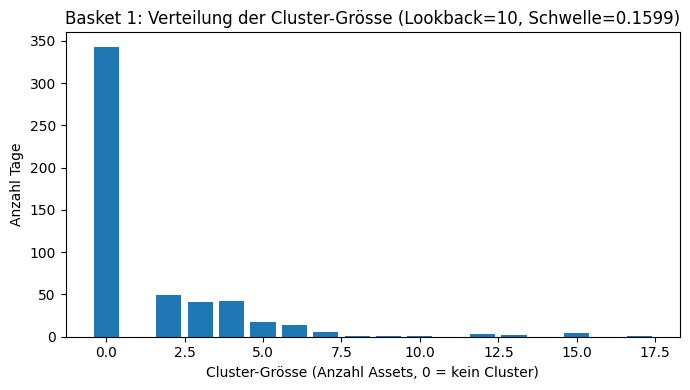

Basket 1: Median=0, Mittelwert=1.46, Anteil ohne Cluster=65.3%
Basket 1 (nur Tage mit Cluster): Median=4, Mittelwert=4.20


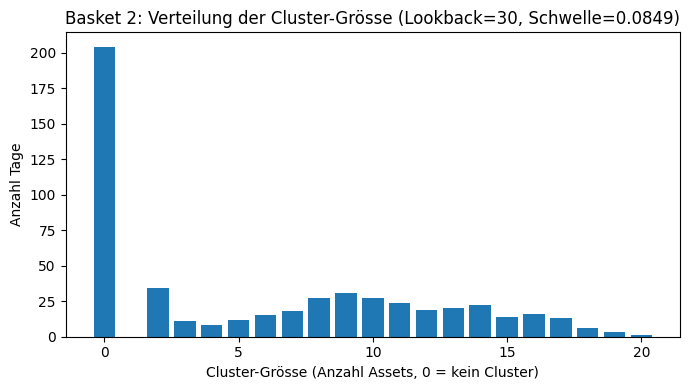

Basket 2: Median=5, Mittelwert=5.92, Anteil ohne Cluster=38.9%
Basket 2 (nur Tage mit Cluster): Median=10, Mittelwert=9.68


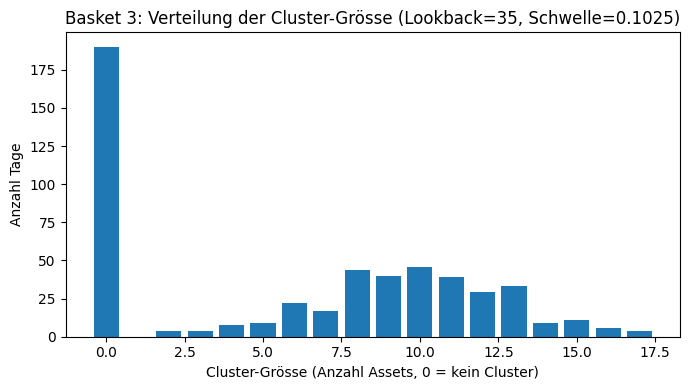

Basket 3: Median=8, Mittelwert=6.18, Anteil ohne Cluster=36.9%
Basket 3 (nur Tage mit Cluster): Median=10, Mittelwert=9.79


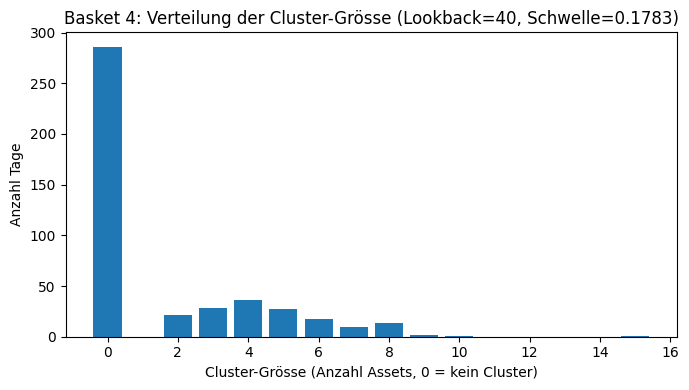

Basket 4: Median=0, Mittelwert=1.65, Anteil ohne Cluster=64.6%
Basket 4 (nur Tage mit Cluster): Median=4, Mittelwert=4.66


In [16]:
# --- Cluster-Grösse: Histogramm pro Basket ---
for label in basket_labels:
    sizes = [r[1] for r in cluster_size_by_basket[label]]
    if not sizes:
        print(f"{label}: keine Werte gesammelt.")
        continue

    max_size = max(sizes)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(sizes, bins=range(max_size + 2), align="left", rwidth=0.8)
    ax.set_xlabel("Cluster-Grösse (Anzahl Assets, 0 = kein Cluster)")
    ax.set_ylabel("Anzahl Tage")
    ax.set_title(
        f"{label}: Verteilung der Cluster-Grösse "
        f"(Lookback={BEST_LOOKBACK[label]}, Schwelle={BEST_THRESHOLD[label]:.4f})"
    )
    plt.tight_layout()
    plt.show()

    sizes_arr = np.asarray(sizes)
    print(
        f"{label}: Median={np.median(sizes_arr):.0f}, Mittelwert={np.mean(sizes_arr):.2f}, "
        f"Anteil ohne Cluster={100 * np.mean(sizes_arr == 0):.1f}%"
    )

    nonzero = sizes_arr[sizes_arr > 0]
    if len(nonzero):
        print(
            f"{label} (nur Tage mit Cluster): Median={np.median(nonzero):.0f}, "
            f"Mittelwert={np.mean(nonzero):.2f}"
        )
    else:
        print(f"{label}: an keinem Tag ein Cluster gefunden.")

## Relative Cluster-Grösse (Anteil am Basket)

Absolute Cluster-Grössen sind zwischen den vier Baskets kaum vergleichbar, da die Basket-Grössen stark variieren (Basket 1 hat i.d.R. deutlich mehr Assets als Basket 4). Hier zusätzlich `cluster_size / basket_total` als Anteil pro Tag -- macht die vier Baskets direkt gegenüberstellbar. Nutzt dieselben Rohdaten wie oben (`cluster_size_by_basket`), keine Neuberechnung nötig.

In [17]:
# --- Relative Cluster-Grösse über die Zeit pro Basket (Anteil am Basket) ---
# Gleiche Rohdaten wie oben (cluster_size_by_basket), aber cluster_size / basket_total
# statt absoluter Anzahl -- macht die vier (unterschiedlich grossen) Baskets direkt
# vergleichbar: "wie viel Prozent des jeweiligen Baskets bleibt im gefundenen Cluster?"
fig = go.Figure()
for i, label in enumerate(basket_labels):
    records = cluster_size_by_basket[label]
    if not records:
        continue
    color = _BASKET_COLORS[i % len(_BASKET_COLORS)]
    dates = [r[0] for r in records]
    rel_sizes = [r[1] / r[2] for r in records]

    fig.add_trace(go.Scatter(
        x=dates, y=rel_sizes, mode="lines+markers", name=label,
        line={"color": color},
    ))

fig.update_layout(
    title=(
        "Relative Cluster-Grösse über die Zeit pro Basket (Klick auf Legende blendet Serien aus)<br>"
        "<sub>Kalibrierungszeitraum, kalibrierte Hyperparameter -- Anteil = Cluster-Grösse / Basket-Grösse an dem Tag</sub>"
    ),
    xaxis_title="Datum",
    yaxis_title="Anteil des Baskets im Cluster",
    yaxis={"tickformat": ".0%", "range": [0, 1]},
    height=550,
)
fig.show()

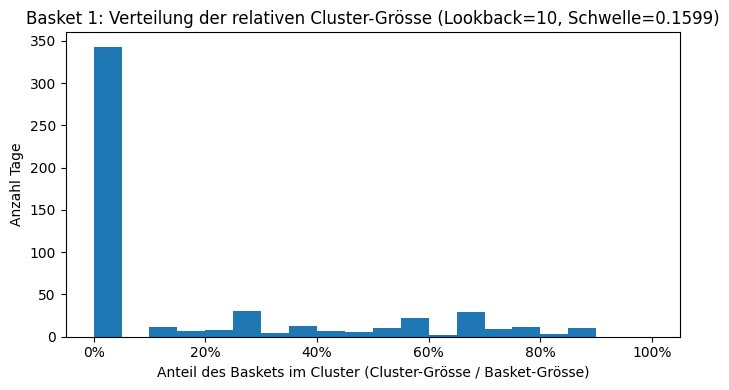

Basket 1: Median=0.0%, Mittelwert=17.0%, Anteil ohne Cluster=65.3%
Basket 1 (nur Tage mit Cluster): Median=50.0%, Mittelwert=49.1%


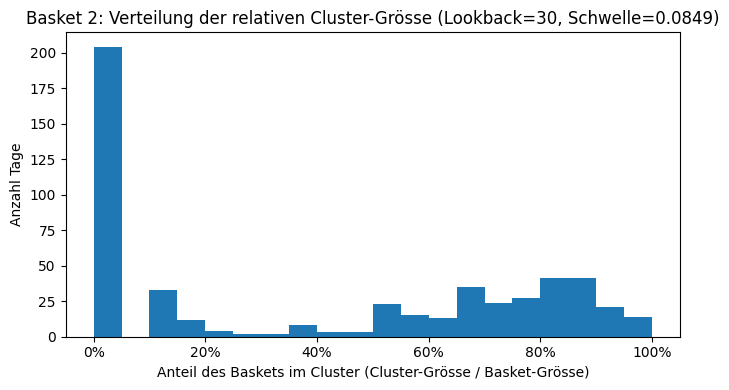

Basket 2: Median=36.4%, Mittelwert=39.6%, Anteil ohne Cluster=38.9%
Basket 2 (nur Tage mit Cluster): Median=71.4%, Mittelwert=64.7%


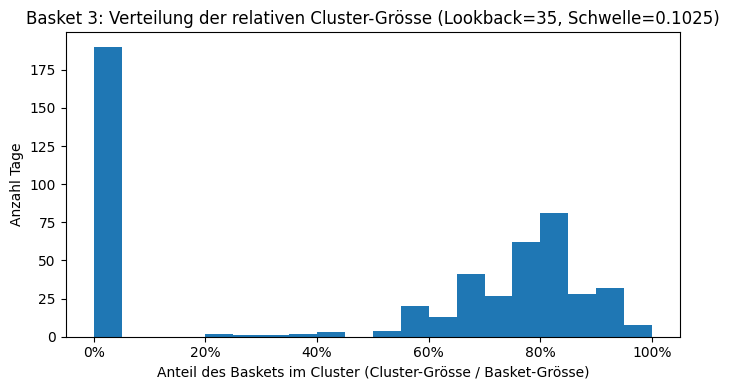

Basket 3: Median=66.7%, Mittelwert=48.1%, Anteil ohne Cluster=36.9%
Basket 3 (nur Tage mit Cluster): Median=77.8%, Mittelwert=76.3%


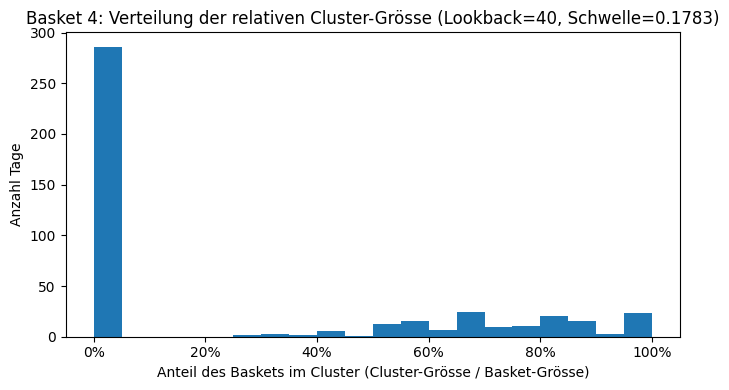

Basket 4: Median=0.0%, Mittelwert=25.5%, Anteil ohne Cluster=64.6%
Basket 4 (nur Tage mit Cluster): Median=71.4%, Mittelwert=71.9%


In [18]:
# --- Relative Cluster-Grösse: Histogramm pro Basket ---
for label in basket_labels:
    records = cluster_size_by_basket[label]
    rel_sizes = [r[1] / r[2] for r in records]
    if not rel_sizes:
        print(f"{label}: keine Werte gesammelt.")
        continue

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(rel_sizes, bins=20, range=(0, 1))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set_xlabel("Anteil des Baskets im Cluster (Cluster-Grösse / Basket-Grösse)")
    ax.set_ylabel("Anzahl Tage")
    ax.set_title(
        f"{label}: Verteilung der relativen Cluster-Grösse "
        f"(Lookback={BEST_LOOKBACK[label]}, Schwelle={BEST_THRESHOLD[label]:.4f})"
    )
    plt.tight_layout()
    plt.show()

    rel_arr = np.asarray(rel_sizes)
    print(
        f"{label}: Median={np.median(rel_arr):.1%}, Mittelwert={np.mean(rel_arr):.1%}, "
        f"Anteil ohne Cluster={100 * np.mean(rel_arr == 0):.1f}%"
    )

    nonzero = rel_arr[rel_arr > 0]
    if len(nonzero):
        print(
            f"{label} (nur Tage mit Cluster): Median={np.median(nonzero):.1%}, "
            f"Mittelwert={np.mean(nonzero):.1%}"
        )
    else:
        print(f"{label}: an keinem Tag ein Cluster gefunden.")

## Überschneidungen: Tage ohne Cluster über mehrere Baskets hinweg

Aus `cluster_size_by_basket` (dieselben Stichtage für alle Baskets, siehe oben) wird eine breite Tabelle gebaut: Zeilen = Datum, Spalten = Basket, Werte = Cluster-Grösse (`NaN`, falls der Basket an dem Tag keine gültige Beobachtung hat, z.B. zu wenige Assets -- **nicht** dasselbe wie `0`). Auf dieser Basis: Verteilung der Anzahl gleichzeitig "leerer" Baskets pro Tag, deren Verlauf über die Zeit, und eine paarweise Überschneidungs-Heatmap.

In [19]:
# --- Breite Tabelle (Datum x Basket -> Cluster-Grösse) + Null-Cluster-Zählung pro Tag ---
_records = [
    {"date": t, "basket": label, "cluster_size": size}
    for label in basket_labels
    for t, size, _total in cluster_size_by_basket[label]
]
cluster_size_df = pd.DataFrame(_records).pivot(index="date", columns="basket", values="cluster_size")
cluster_size_df = cluster_size_df[basket_labels]  # feste Spaltenreihenfolge Basket 1..4

n_available = cluster_size_df.notna().sum(axis=1)
n_zero = (cluster_size_df == 0).sum(axis=1)

print(f"Tage insgesamt: {len(cluster_size_df)}")
for k in range(len(basket_labels) + 1):
    n_days = int((n_zero == k).sum())
    print(f"  {k} von {len(basket_labels)} Baskets gleichzeitig ohne Cluster: {n_days} Tage")

all_zero_mask = (n_zero == n_available) & (n_available == len(basket_labels))
all_zero_dates = cluster_size_df.index[all_zero_mask]
print(f"\nTage, an denen ALLE {len(basket_labels)} Baskets gleichzeitig 0 Cluster haben: {len(all_zero_dates)}")
if len(all_zero_dates):
    print("Beispieldaten:", [d.date().isoformat() for d in all_zero_dates[:15]])

Tage insgesamt: 525
  0 von 4 Baskets gleichzeitig ohne Cluster: 73 Tage
  1 von 4 Baskets gleichzeitig ohne Cluster: 142 Tage
  2 von 4 Baskets gleichzeitig ohne Cluster: 122 Tage
  3 von 4 Baskets gleichzeitig ohne Cluster: 115 Tage
  4 von 4 Baskets gleichzeitig ohne Cluster: 73 Tage

Tage, an denen ALLE 4 Baskets gleichzeitig 0 Cluster haben: 73
Beispieldaten: ['2024-09-20', '2024-09-21', '2024-09-22', '2024-10-01', '2024-10-04', '2024-10-18', '2024-10-19', '2024-10-20', '2024-10-21', '2024-10-22', '2024-10-23', '2024-10-24', '2024-10-25', '2024-10-31', '2024-11-01']


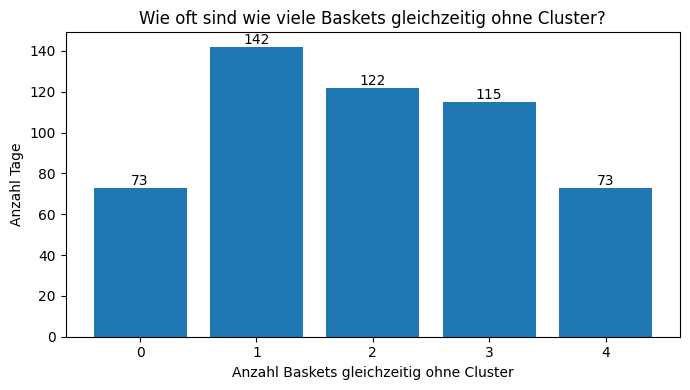

In [20]:
# --- Verteilung: Anzahl gleichzeitig leerer Baskets pro Tag (Balkendiagramm) ---
counts = [int((n_zero == k).sum()) for k in range(len(basket_labels) + 1)]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(basket_labels) + 1), counts)
ax.set_xticks(range(len(basket_labels) + 1))
ax.set_xlabel("Anzahl Baskets gleichzeitig ohne Cluster")
ax.set_ylabel("Anzahl Tage")
ax.set_title("Wie oft sind wie viele Baskets gleichzeitig ohne Cluster?")
for x, c in enumerate(counts):
    ax.text(x, c, str(c), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [21]:
# --- Verlauf über die Zeit: Anzahl leerer Baskets pro Tag (Plotly) ---
# Zeigt, ob "0 Cluster" über die Zeit gleichmässig verteilt ist oder in
# Phasen (z.B. marktweite Unkorreliertheit) gehäuft gleichzeitig auftritt.
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=cluster_size_df.index, y=n_zero, mode="lines+markers",
    name="Anzahl Baskets ohne Cluster",
    line={"color": "#d62728"},
))
fig.update_layout(
    title="Anzahl gleichzeitig leerer Baskets über die Zeit (Kalibrierungszeitraum)",
    xaxis_title="Datum",
    yaxis_title=f"Anzahl Baskets ohne Cluster (von {len(basket_labels)})",
    yaxis={"range": [-0.3, len(basket_labels) + 0.3], "dtick": 1},
    height=400,
)
fig.show()

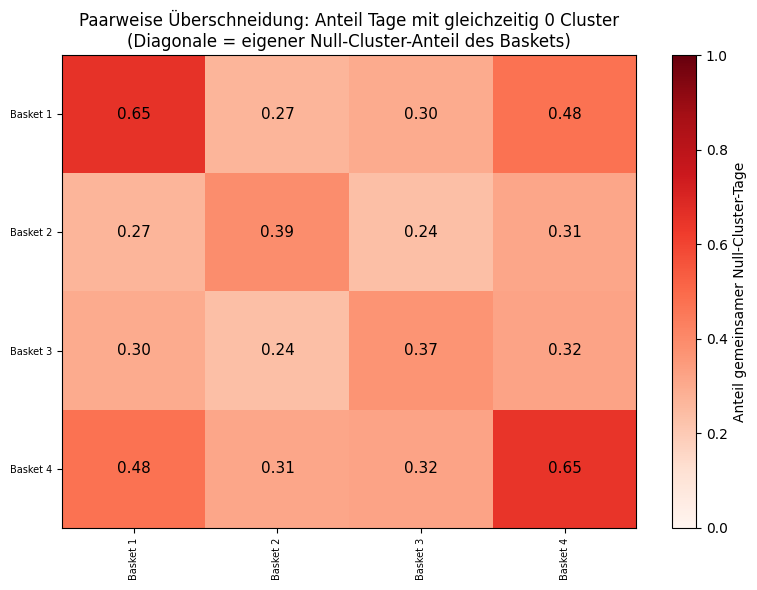

In [22]:
# --- Paarweise Überschneidung: Anteil gemeinsamer Null-Cluster-Tage je Basket-Paar ---
# Zelle (i, j) = Anteil der Tage (unter den Tagen, an denen BEIDE Baskets eine
# gültige Beobachtung haben), an denen Basket i UND Basket j gleichzeitig 0
# Cluster haben. Diagonale = eigener Null-Cluster-Anteil des Baskets.
n_baskets = len(basket_labels)
overlap_matrix = np.full((n_baskets, n_baskets), np.nan)
for i, li in enumerate(basket_labels):
    for j, lj in enumerate(basket_labels):
        both_valid = cluster_size_df[li].notna() & cluster_size_df[lj].notna()
        if both_valid.sum() == 0:
            continue
        both_zero = (cluster_size_df[li] == 0) & (cluster_size_df[lj] == 0) & both_valid
        overlap_matrix[i, j] = both_zero.sum() / both_valid.sum()

_ = plot_correlation_heatmap(
    overlap_matrix, basket_labels,
    value_range=(0, 1.0),
    cmap="Reds",
    colorbar_label="Anteil gemeinsamer Null-Cluster-Tage",
    title="Paarweise Überschneidung: Anteil Tage mit gleichzeitig 0 Cluster\n(Diagonale = eigener Null-Cluster-Anteil des Baskets)",
)